| **Inicio**         | **Siguiente 2**                                    |
| ------------------  | -------------------------------------------------- |
| [🏠](../README.md)  | [⏩](./6_2_Root_finding.ipynb) |

# 1. ¿Qué significa "error" en cálculo científico?

Supongamos que el valor matemático exacto es

$x=3.141592653589793\ldots$

pero nuestro algoritmo produce

$\hat{x}=3.14$.

Entonces existe una diferencia:

$x-\hat{x}$.

En análisis numérico queremos cuantificarla.

Una distinción importante:

$\boxed{\text{error} \neq \text{equivocación}}$

Un algoritmo puede estar perfectamente implementado y aun así tener error porque utiliza aproximaciones, discretización y aritmética finita.

Esto ocurre constantemente en SciML.

# 2. Error absoluto

El **error absoluto** es:

$E_{\mathrm{abs}}
=$
$|x-\hat{x}|
$

donde:

- $(x)$: valor exacto;
- $(\hat{x})$: aproximación.

Por ejemplo:

$x=100$

y

$\hat{x}=98$.

Entonces:

$E_{\mathrm{abs}}
=$
$|100-98|
=$
$2$.

## Ejemplo de vida diaria

Supongamos que Google Maps estima una distancia de:

$10.2\text{ km}$

mientras que la distancia real es:

$10.0\text{ km}$.

Entonces:

$E_{\mathrm{abs}}
=$
$|10-10.2|
=$
$0.2\text{ km}$.

Es decir:

$200\text{ metros}$.

# 3. Problema del error absoluto

Ahora considera dos mediciones.

### Caso A

Distancia real:

$1000\text{ km}$

estimación:

$999\text{ km}$.

Error:

$1\text{ km}$.

### Caso B

Distancia real:

$2\text{ km}$

estimación:

$1\text{ km}$.

Error:

$1\text{ km}$.

El error absoluto es idéntico:

$E_{\mathrm{abs}}=$ $1$.

Pero obviamente los errores no tienen la misma importancia.

En A:

$1/1000=0.001$.

En B:

$1/2=0.5$.

Necesitamos **error relativo**.

# 4. Error relativo

Se define:

$E_{\mathrm{rel}}
=$
$\frac{|x-\hat{x}|}{|x|}$

si $(x\neq0)$.

Y en porcentaje:

$E_{\%}
=$
$100E_{\mathrm{rel}}$

Para A:

$E_{\mathrm{rel}}
=$
$\frac1{1000}
=$
$0.001$

$E_\%=$ $0.1\%$.

Para B:

$E_{\mathrm{rel}}
=$
$\frac12
=$
$0.5$

$E_\%=50\%$.

Ahora vemos claramente la diferencia.

# 5. Visualización: absoluto vs relativo

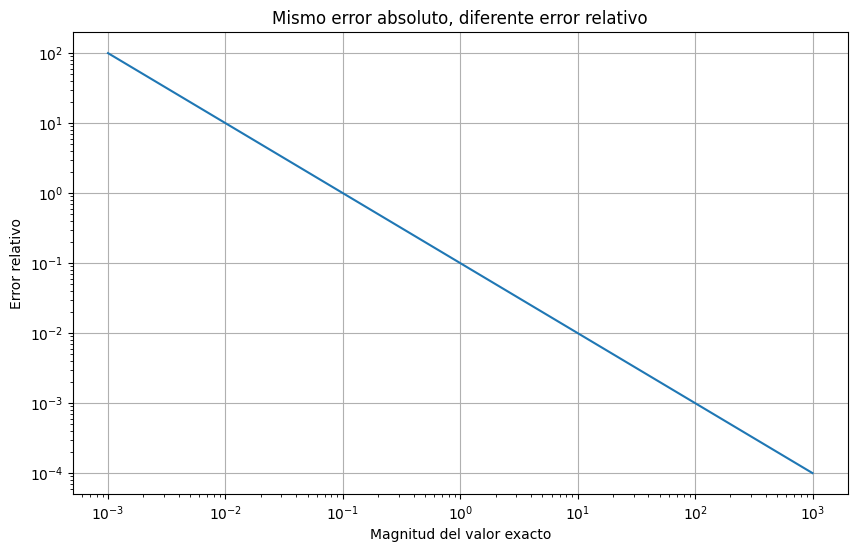

In [1]:
import numpy as np
import matplotlib.pyplot as plt

true_values = np.logspace(-3, 3, 500)

absolute_error = 0.1

approximations = true_values + absolute_error

relative_errors = (
    np.abs(true_values - approximations)
    / np.abs(true_values)
)

plt.figure(figsize=(10, 6))

plt.loglog(
    true_values,
    relative_errors
)

plt.xlabel("Magnitud del valor exacto")
plt.ylabel("Error relativo")

plt.title(
    "Mismo error absoluto, diferente error relativo"
)

plt.grid(True)

plt.show()

Aquí mantuvimos:

$E_{\mathrm{abs}}=$ $0.1$
\]

constante.

Pero cuando el valor verdadero se acerca a cero:

$E_{\mathrm{rel}}$

crece muchísimo.

Esta observación será importante cuando evalúes modelos científicos.

# 6. Error de truncamiento

Ahora entramos en análisis numérico.

El **truncation error** aparece cuando reemplazamos un proceso matemático infinito o exacto por una aproximación finita.

Por ejemplo:

$e^x
=$
$1+x+\frac{x^2}{2!}$
$+\frac{x^3}{3!}
+\cdots$

es una serie infinita.

Una computadora podría utilizar solamente:

$e^x
\approx
1+x+\frac{x^2}{2}$.

Hemos **truncado** la serie.

El error resultante es un error de truncamiento.

# 7. Ejemplo con $(e^x)$

Para:

$x=1$

sabemos:

$e\approx2.718281828$.

Utilizando:

$1+x$

obtenemos:

$2$.

Añadiendo:

$\frac{x^2}{2}$

obtenemos:

$2.5$.

Añadiendo más términos nos acercamos a $(e)$.

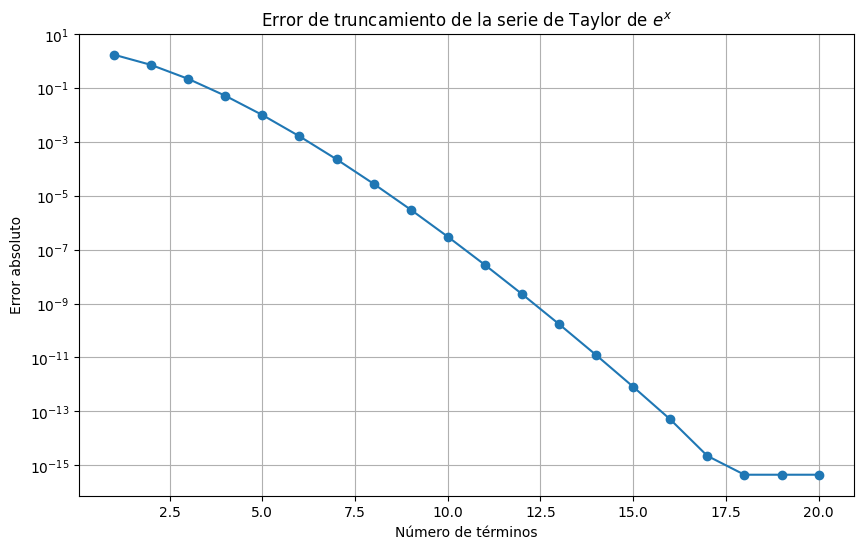

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math

x = 1.0

exact = np.exp(x)

max_terms = 20

errors = []

approximation = 0.0

factorial = 1.0

for n in range(max_terms):

    if n > 0:
        factorial *= n

    approximation += x**n / factorial

    error = abs(exact - approximation)

    errors.append(error)

terms = np.arange(1, max_terms + 1)

plt.figure(figsize=(10, 6))

plt.semilogy(
    terms,
    errors,
    marker="o"
)

plt.xlabel("Número de términos")
plt.ylabel("Error absoluto")

plt.title(
    "Error de truncamiento de la serie de Taylor de $e^x$"
)

plt.grid()

plt.show()

Al añadir términos, el error inicialmente disminuye drásticamente.

Esto es **convergencia de una aproximación**.

# 8. Truncation error en derivadas

Este caso es mucho más importante para SciML.

Sabemos:

$f'(x)
=$
$\lim_{h\rightarrow0}
\frac{f(x+h)-f(x)}{h}$.

En una computadora no podemos usar literalmente:

$h=0$.

Entonces usamos:

$f'(x)
\approx
\frac{f(x+h)-f(x)}{h}$

Esto es **forward finite difference**.

Pero ¿qué error tiene?

Utilizamos Taylor:

$f(x+h)
=$
$f(x)
+$
$hf'(x)
+$
$\frac{h^2}{2}f''(x)
+$
$O(h^3)$.

Restamos $f(x)$:

$f(x+h)-f(x)
=$
$hf'(x)
+$
$\frac{h^2}{2}f''(x)
+$
$O(h^3)$.

Dividimos entre $(h)$:

$\frac{f(x+h)-f(x)}{h}
=$
$f'(x)
+$
$\frac{h}{2}f''(x)
+$
$O(h^2)$.

Por tanto:

$E_{\mathrm{trunc}}
=$
$O(h)$

para forward difference.

# 9. Una aproximación mejor: diferencia central

Podemos usar:

$\boxed{
f'(x)
\approx
\frac{f(x+h)-f(x-h)}{2h}
}$

Su error es:

$E_{\mathrm{trunc}}
=$
$O(h^2)$

Esto significa que disminuye mucho más rápidamente.

Comparemos ambos.

Tomemos:

$f(x)=\sin(x)$

y sabemos exactamente:

$f'(x)=\cos(x)$

En:

$x=1$,

el valor exacto es:

$\cos(1)$.

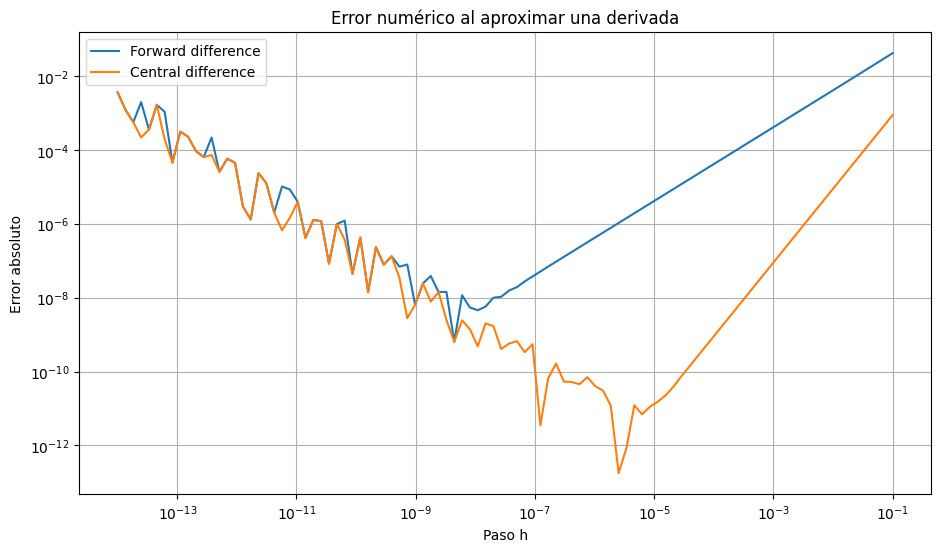

In [4]:
import numpy as np
import matplotlib.pyplot as plt

x = 1.0

exact = np.cos(x)

h_values = np.logspace(
    -1,
    -14,
    100
)

forward_errors = []
central_errors = []

for h in h_values:

    forward = (
        np.sin(x + h)
        - np.sin(x)
    ) / h

    central = (
        np.sin(x + h)
        - np.sin(x - h)
    ) / (2*h)

    forward_errors.append(
        abs(forward - exact)
    )

    central_errors.append(
        abs(central - exact)
    )

plt.figure(figsize=(11, 6))

plt.loglog(
    h_values,
    forward_errors,
    label="Forward difference"
)

plt.loglog(
    h_values,
    central_errors,
    label="Central difference"
)

plt.xlabel("Paso h")
plt.ylabel("Error absoluto")

plt.title(
    "Error numérico al aproximar una derivada"
)

plt.legend()
plt.grid()

plt.show()

Y aquí aparece algo sorprendente.

Esperaríamos:

$h\rightarrow0
\quad\Rightarrow\quad
error\rightarrow0$.

Pero eso **no continúa indefinidamente**.

En algún momento el error vuelve a aumentar.

¿Por qué?

Por **round-off error**.

# 10. Round-off error

Las computadoras no representan números reales con precisión infinita.

Por ejemplo:

$\frac13
=$
$0.333333333333333\ldots$


requiere infinitos dígitos.

Una computadora almacena una aproximación.

Lo mismo ocurre con:

$\pi,\quad
\sqrt2,\quad
0.1,\quad
e$.

Esto produce:

$\boxed{\text{round-off error}}$

o error de redondeo.

# 11. Floating point

La mayoría de los cálculos científicos utiliza números en **punto flotante**.

Conceptualmente:

$x
=$
$(-1)^s
\times
m
\times
2^e$

donde:

- $(s)$: signo;
- $(m)$: mantisa/significand;
- $(e)$: exponente.

En `float64` tenemos aproximadamente:

- 1 bit de signo;
- 11 bits de exponente;
- 52 bits almacenados para la fracción de la mantisa.

Eso proporciona aproximadamente:

$15-16$

dígitos decimales significativos.


# 12. El famoso problema de 0.1

Python:

In [5]:
print(0.1 + 0.2)

0.30000000000000004


produce típicamente algo equivalente a:

```text
0.30000000000000004
```

porque:

$0.1$

no tiene representación binaria finita exacta.

Puedes verlo con:

In [6]:
print(format(0.1, ".60f"))

0.100000000000000005551115123125782702118158340454101562500000





Obtendrás algo parecido a:

```text
0.100000000000000005551115123125...
```

No significa que Python esté "mal".

Significa que estás trabajando con una aproximación binaria.

# 13. Machine epsilon

Un número importantísimo es:

$\boxed{\epsilon_{\text{machine}}}$

Para `float64`:

In [7]:
import numpy as np

print(np.finfo(np.float64))

Machine parameters for float64
---------------------------------------------------------------
precision =  15   resolution = 1.0000000000000001e-15
machep =    -52   eps =        2.2204460492503131e-16
negep =     -53   epsneg =     1.1102230246251565e-16
minexp =  -1022   tiny =       2.2250738585072014e-308
maxexp =   1024   max =        1.7976931348623157e+308
nexp =       11   min =        -max
smallest_normal = 2.2250738585072014e-308   smallest_subnormal = 4.9406564584124654e-324
---------------------------------------------------------------



y específicamente:

In [8]:
eps = np.finfo(np.float64).eps

print(eps)

2.220446049250313e-16


aproximadamente:

$\epsilon_{\text{machine}}
\approx2.22\times10^{-16}$

Una interpretación aproximada es:

> Cerca de 1, representa la escala de separación relativa entre números `float64` consecutivos.

# 14. Visualicemos la separación entre floats

Los números floating point **no están uniformemente distribuidos** en la recta real.

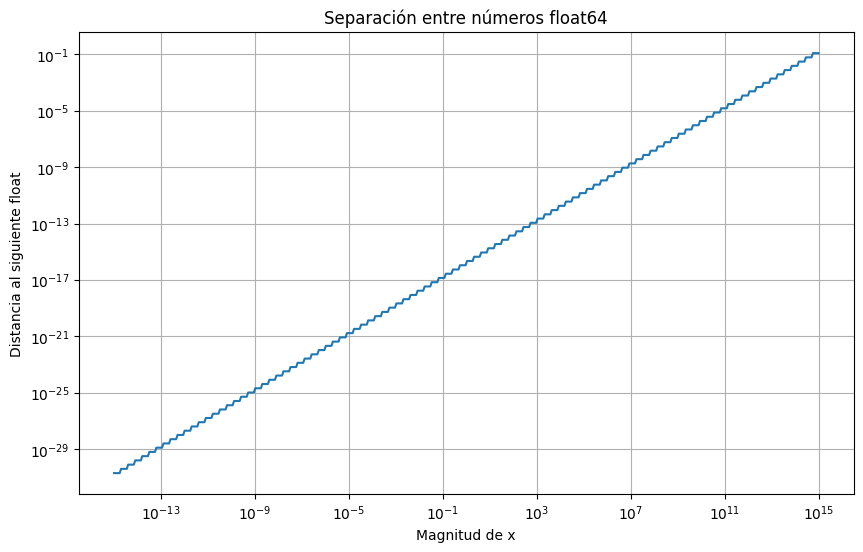

In [9]:
import numpy as np
import matplotlib.pyplot as plt

magnitudes = np.logspace(
    -15,
    15,
    500
)

spacing = np.spacing(magnitudes)

plt.figure(figsize=(10, 6))

plt.loglog(
    magnitudes,
    spacing
)

plt.xlabel("Magnitud de x")
plt.ylabel("Distancia al siguiente float")

plt.title(
    "Separación entre números float64"
)

plt.grid()

plt.show()

Cuando los números son grandes, la distancia entre floats representables también aumenta.

Esta es una propiedad crucial del floating point.

# 15. Catastrophic cancellation

Este problema es especialmente peligroso.

Consideremos:

$f(x)=$ $\sqrt{x+1}-\sqrt{x}$.

Para $(x)$ muy grande, ambos números son casi iguales.

Por ejemplo:

$\sqrt{x+1}
\approx
\sqrt{x}$.

Al restarlos:

$\text{número grande}
-$
$\text{número casi igual}$

podemos perder muchos dígitos significativos.

Matemáticamente podemos racionalizar:

$\sqrt{x+1}-\sqrt{x}$

multiplicando por:

$\frac{\sqrt{x+1}+\sqrt{x}}
{\sqrt{x+1}+\sqrt{x}}$.

Entonces:

$\sqrt{x+1}-\sqrt{x}
=$
$\frac{1}
{\sqrt{x+1}+\sqrt{x}}$

La segunda expresión es numéricamente mucho más estable.

# 16. Experimento de cancelación

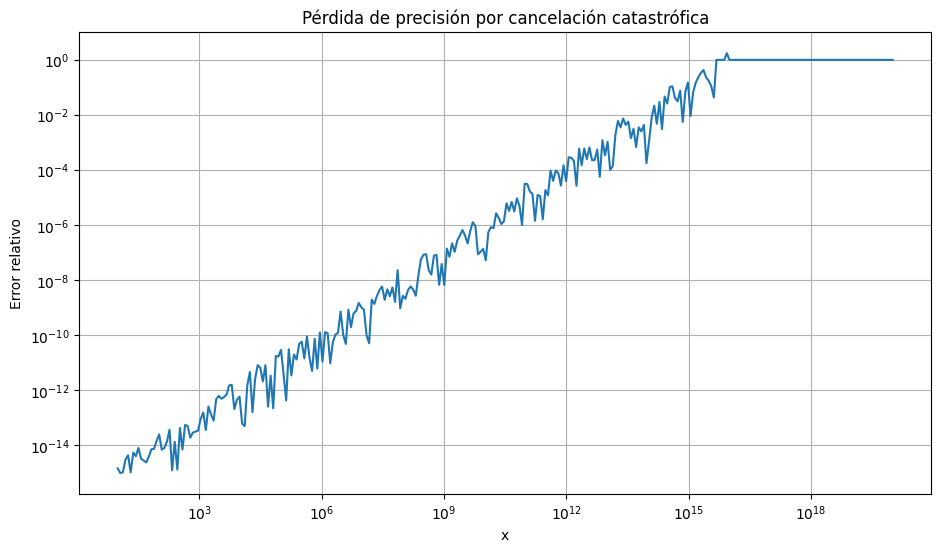

In [10]:
import numpy as np
import matplotlib.pyplot as plt

x_values = np.logspace(
    1,
    20,
    300
)

naive = (
    np.sqrt(x_values + 1)
    - np.sqrt(x_values)
)

stable = (
    1
    /
    (
        np.sqrt(x_values + 1)
        + np.sqrt(x_values)
    )
)

relative_error = (
    np.abs(naive - stable)
    /
    np.abs(stable)
)

plt.figure(figsize=(11, 6))

plt.loglog(
    x_values,
    relative_error
)

plt.xlabel("x")
plt.ylabel("Error relativo")

plt.title(
    "Pérdida de precisión por cancelación catastrófica"
)

plt.grid()

plt.show()

Para valores suficientemente grandes, la expresión ingenua empieza a perder precisión gravemente.

Esto demuestra algo importante:

$\boxed{
\text{expresiones matemáticamente equivalentes}
\not\Rightarrow
\text{algoritmos numéricamente equivalentes}
}$

# 17. Truncamiento vs round-off

Volvamos a la derivada:

$f'(x)
\approx
\frac{f(x+h)-f(x)}{h}$.

Tenemos dos errores compitiendo.

### Truncamiento

Aproximadamente:

$E_T\sim Ch$.

Disminuye cuando:

$h\downarrow$.

### Redondeo

Aproximadamente puede comportarse como:

$E_R\sim\frac{\epsilon_{\text{machine}}}{h}$

Aumenta cuando:

$h\downarrow$

Por tanto:

$\boxed{
E_{\mathrm{total}}
\approx
Ch+
\frac{\epsilon}{h}
}$

Esta ecuación es tremendamente importante.

# 18. La curva en U del error

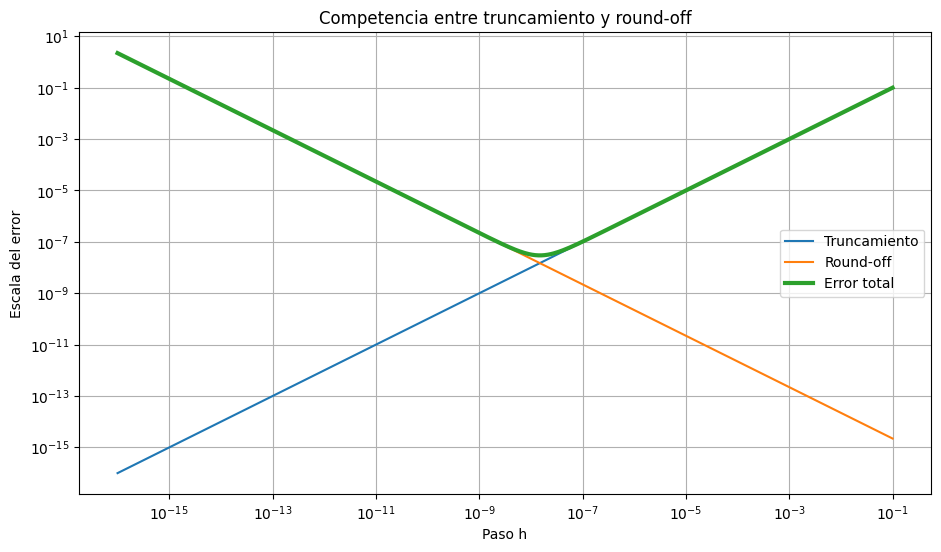

In [11]:
import numpy as np
import matplotlib.pyplot as plt

eps = np.finfo(float).eps

h = np.logspace(
    -16,
    -1,
    500
)

truncation = h

roundoff = eps / h

total = truncation + roundoff

plt.figure(figsize=(11, 6))

plt.loglog(
    h,
    truncation,
    label="Truncamiento"
)

plt.loglog(
    h,
    roundoff,
    label="Round-off"
)

plt.loglog(
    h,
    total,
    linewidth=3,
    label="Error total"
)

plt.xlabel("Paso h")
plt.ylabel("Escala del error")

plt.title(
    "Competencia entre truncamiento y round-off"
)

plt.legend()
plt.grid()

plt.show()

Esta gráfica explica por qué:

$\boxed{
\text{usar un paso más pequeño no siempre produce mayor precisión}
}$

Existe un punto óptimo.

Esto será muy importante en:

- diferencias finitas;
- ODE solvers;
- PDE solvers;
- optimización;
- gradient checking;
- SciML.

# 19. Ahora: estabilidad

Este concepto suele confundirse con conditioning.

Son cosas distintas.

La **estabilidad numérica** pregunta:

> ¿El algoritmo amplifica excesivamente pequeños errores durante el cálculo?

Consideremos una ODE:

$y'=-\lambda y$.


Con:

$y(0)=1$

La solución exacta es:

$y(t)=$ $e^{-\lambda t}$

y tiende a cero.

# 20. Euler explícito

Euler aproxima:

$y_{n+1}
=$
$y_n+h f(t_n,y_n)$.

Como:

$f=-\lambda y$,

tenemos:

$y_{n+1}
=$
$y_n-h\lambda y_n$.

Por tanto:

$y_{n+1}
=$
$(1-h\lambda)y_n$

Para que la solución numérica disminuya necesitamos:

$|1-h\lambda|<1$.

Esto implica:

$
0<h\lambda<2$

Ésta es una **condición de estabilidad**.

# 21. Ejemplo: algoritmo estable e inestable


Tomemos:

$y'=-10y$.

Entonces:

$\lambda=10$.

Euler necesita:

$h<0.2$.

Probemos:

$h=0.05,
\quad
h=0.15,
\quad
h=0.21,
\quad
h=0.3$.

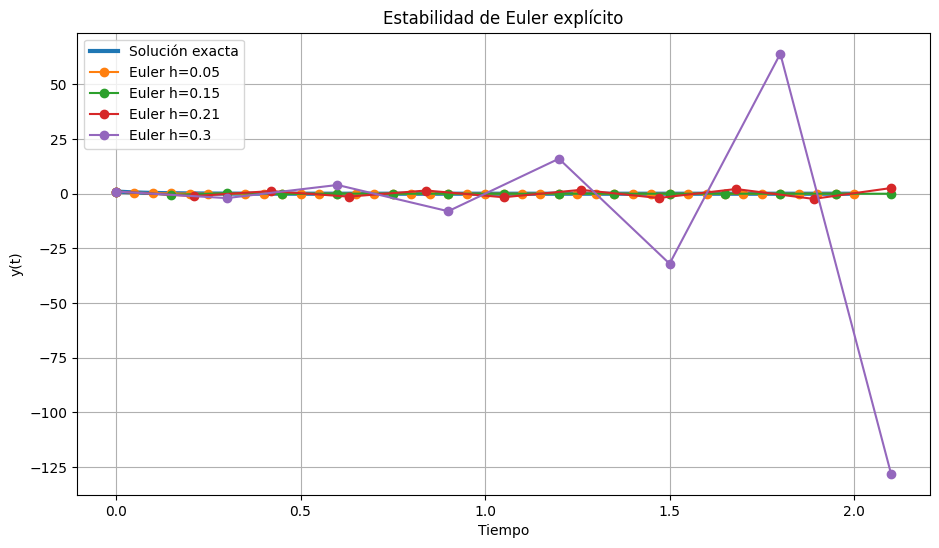

In [12]:
import numpy as np
import matplotlib.pyplot as plt

lam = 10.0

T = 2.0

h_values = [
    0.05,
    0.15,
    0.21,
    0.30
]

plt.figure(figsize=(11, 6))

t_exact = np.linspace(
    0,
    T,
    1000
)

y_exact = np.exp(
    -lam * t_exact
)

plt.plot(
    t_exact,
    y_exact,
    linewidth=3,
    label="Solución exacta"
)

for h in h_values:

    t = np.arange(
        0,
        T + h,
        h
    )

    y = np.zeros_like(t)

    y[0] = 1

    for n in range(len(t)-1):

        y[n+1] = (
            y[n]
            - h * lam * y[n]
        )

    plt.plot(
        t,
        y,
        marker="o",
        label=f"Euler h={h}"
    )

plt.xlabel("Tiempo")
plt.ylabel("y(t)")

plt.title(
    "Estabilidad de Euler explícito"
)

plt.legend()
plt.grid()

plt.show()

Para:

$h=0.3$

la solución numérica puede explotar u oscilar, aunque la solución física exacta:

$e^{-10t}$

debería desaparecer.

Eso es grave.

El modelo físico es estable.

La **simulación numérica no lo es**.

# 22. Ejemplo de vida real: simulación física

Imagina que simulas la temperatura de un procesador.

La física dice:

$T(t)\rightarrow T_{\text{ambiente}}$.

Pero eliges un método/paso temporal inestable.

La computadora podría predecir:

$80^\circ
\rightarrow
20^\circ
\rightarrow
150^\circ
\rightarrow
-100^\circ
\rightarrow
400^\circ$

aunque nada de eso ocurre físicamente.

Por eso:

$\boxed{
\text{una simulación que corre sin errores de Python}
\neq
\text{una simulación correcta}
}$

# 23. Convergencia

Ahora preguntamos:

> Cuando hacemos la discretización cada vez más fina, ¿la solución numérica se acerca a la solución exacta?

Si:

$h\rightarrow0$

y

$y_h\rightarrow y$ ,

el método es **convergente**.

Formalmente:

$
\lim_{h\rightarrow0}
\|y_h-y\|
=$
$0
$

# 24. Orden de convergencia

Supongamos:

$E(h)\approx Ch^p$.

Entonces $(p)$ es el **orden de convergencia**.

Para Euler:

$p=1$.

Entonces:

$E(h)\sim Ch$.

Si reducimos:

$h\rightarrow\frac h2$,

esperamos aproximadamente:

$E\rightarrow\frac E2$.

Para un método de orden 2:

$E\sim Ch^2$.

Entonces:

$h\rightarrow\frac h2$

produce:

$E\rightarrow\frac E4$.

Para RK4:

$E\sim Ch^4$.

Reducir $(h)$ a la mitad puede reducir el error aproximadamente por:

$2^4=16$.

# 25. Experimento de convergencia: Euler vs RK4

Resolveremos:

$y'=-2y$

$y(0)=1$.

La solución exacta:

$y(t)=$ $e^{-2t}$.

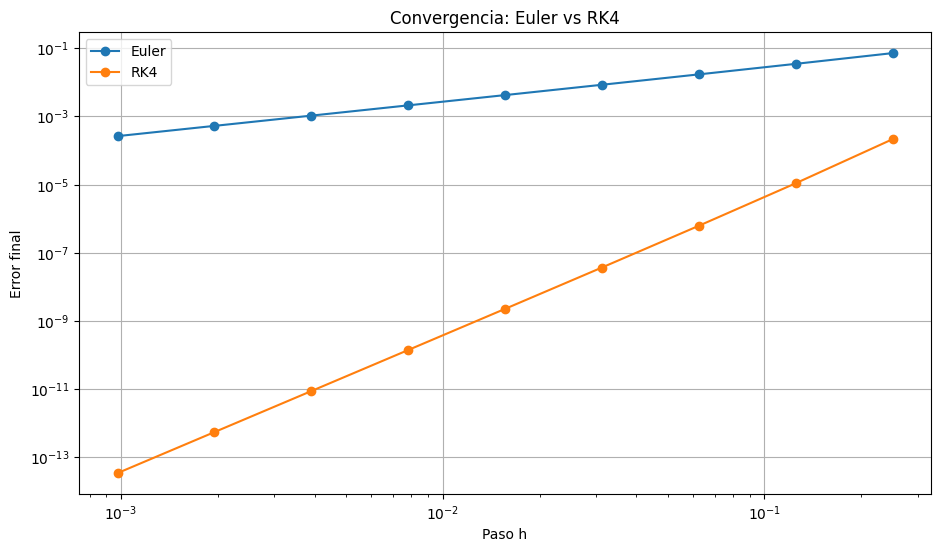

In [13]:
import numpy as np
import matplotlib.pyplot as plt

def f(t, y):
    return -2*y


def euler(h):

    T = 1.0

    N = int(T/h)

    t = 0.0
    y = 1.0

    for _ in range(N):

        y = y + h*f(t, y)

        t += h

    return y


def rk4(h):

    T = 1.0

    N = int(T/h)

    t = 0.0
    y = 1.0

    for _ in range(N):

        k1 = f(t, y)

        k2 = f(
            t + h/2,
            y + h*k1/2
        )

        k3 = f(
            t + h/2,
            y + h*k2/2
        )

        k4 = f(
            t + h,
            y + h*k3
        )

        y = y + (
            h/6
            * (
                k1
                + 2*k2
                + 2*k3
                + k4
            )
        )

        t += h

    return y


h_values = (
    1
    /
    2**np.arange(2, 11)
)

exact = np.exp(-2)

euler_errors = []
rk4_errors = []

for h in h_values:

    euler_errors.append(
        abs(
            euler(h)
            - exact
        )
    )

    rk4_errors.append(
        abs(
            rk4(h)
            - exact
        )
    )


plt.figure(figsize=(11, 6))

plt.loglog(
    h_values,
    euler_errors,
    marker="o",
    label="Euler"
)

plt.loglog(
    h_values,
    rk4_errors,
    marker="o",
    label="RK4"
)

plt.xlabel("Paso h")
plt.ylabel("Error final")

plt.title(
    "Convergencia: Euler vs RK4"
)

plt.legend()
plt.grid()

plt.show()

En escala log-log las pendientes revelan aproximadamente:

$\boxed{p=1}$

para Euler y:

$\boxed{p=4}$

para RK4.

# 26. Conditioning: ahora cambia completamente la pregunta

Aquí está una distinción fundamental.

**Conditioning pertenece al problema.**

**Stability pertenece al algoritmo.**

Supongamos un problema:

$f(x)=y$.

Perturbamos ligeramente la entrada:

$x\rightarrow x+\delta x$.

Si el resultado cambia ligeramente, el problema está **bien condicionado**.

Si una perturbación diminuta produce un cambio enorme:

$\boxed{\text{problema mal condicionado}}$

# 27. Ejemplo con sistemas lineales

Consideremos:

$Ax=b$.

Si una pequeña modificación de $(b)$ produce una modificación enorme en $(x)$, tenemos un sistema mal condicionado.

El número de condición de una matriz es:

$\kappa(A)
=$
$\|A\|
\|A^{-1}\|$

En NumPy:

```python
np.linalg.cond(A)
```

Interpretación aproximada:

$\kappa(A)\approx1$

muy bien condicionado.

$\kappa(A)\gg1$

mal condicionado.

# 28. Ejemplo difícil: dos matrices

Primero:

In [14]:
import numpy as np

A_good = np.array([
    [2.0, 0.0],
    [0.0, 1.0]
])

A_bad = np.array([
    [1.0, 1.0],
    [1.0, 1.000001]
])

print(
    "Condición buena:",
    np.linalg.cond(A_good)
)

print(
    "Condición mala:",
    np.linalg.cond(A_bad)
)

Condición buena: 2.0
Condición mala: 4000002.0003309543


La segunda matriz tiene filas casi linealmente dependientes.

Eso significa que geométricamente está cerca de ser singular.

# 29. Perturbemos los datos

In [15]:
import numpy as np

A = np.array([
    [1.0, 1.0],
    [1.0, 1.000001]
])

x_true = np.array([
    1.0,
    1.0
])

b = A @ x_true

perturbation = np.array([
    0.0,
    1e-7
])

b_perturbed = (
    b
    + perturbation
)

x_original = np.linalg.solve(
    A,
    b
)

x_perturbed = np.linalg.solve(
    A,
    b_perturbed
)

print("x original:")
print(x_original)

print("\nx perturbado:")
print(x_perturbed)

x original:
[1. 1.]

x perturbado:
[0.9 1.1]


Aunque:

$\delta b$

es muy pequeño, el cambio en:

$x$

puede ser muchísimo mayor relativamente.

# 30. Visualización del conditioning

Consideremos las ecuaciones:

$x+y=2$

y

$x+1.000001y=2.000001$.

Son dos líneas casi paralelas.

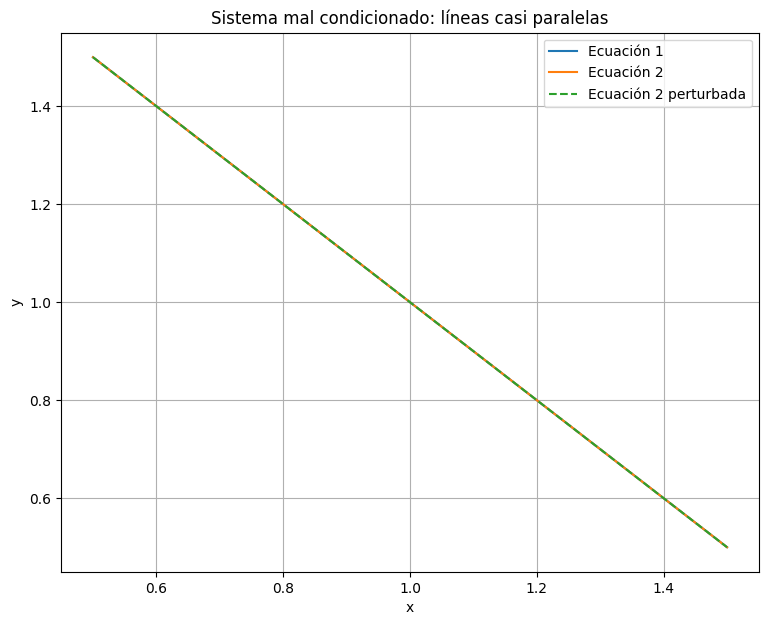

In [16]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(
    0.5,
    1.5,
    1000
)

y1 = 2 - x

y2 = (
    2.000001 - x
) / 1.000001

y2_perturbed = (
    2.0000011 - x
) / 1.000001

plt.figure(figsize=(9, 7))

plt.plot(
    x,
    y1,
    label="Ecuación 1"
)

plt.plot(
    x,
    y2,
    label="Ecuación 2"
)

plt.plot(
    x,
    y2_perturbed,
    linestyle="--",
    label="Ecuación 2 perturbada"
)

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    "Sistema mal condicionado: líneas casi paralelas"
)

plt.legend()
plt.grid()

plt.show()

Esta visualización explica geométricamente el problema.

Si dos líneas se cruzan con un ángulo razonable, mover ligeramente una de ellas cambia poco la intersección.

Pero si son casi paralelas:

$\boxed{
\text{perturbación pequeña}
\rightarrow
\text{gran desplazamiento de la intersección}
}$

# 31. Conditioning no es error numérico

Esta distinción merece memorizarse:

$\text{Conditioning}
=$
$
\text{sensibilidad del problema}
$

mientras que:

$
\text{Stability}
=$
$\text{sensibilidad del algoritmo}
$

Un problema puede estar mal condicionado aunque utilices un algoritmo excelente.

Y un problema perfectamente condicionado puede obtener resultados malos si utilizas un algoritmo inestable.

Idealmente queremos:

$\text{problema bien condicionado}
+
\text{algoritmo estable}
$

# 32. Ejemplo real: estimación de parámetros científicos

Esto conecta directamente con SciML.

Supongamos:

$y=ax+b$.

Queremos encontrar:

$\theta=
\begin{bmatrix}
a\\b
\end{bmatrix}$.

Tenemos:

$X\theta=y$.

La solución de mínimos cuadrados puede escribirse formalmente mediante las **normal equations**:

$X^TX\theta=X^Ty$

por lo que:

$\theta=(X^TX)^{-1}X^Ty$.

Pero aquí existe un problema.

Aproximadamente:
$
\kappa(X^TX)
\approx
\kappa(X)^2
$

Es decir, las ecuaciones normales pueden **empeorar el conditioning**.

Por eso, en computación científica generalmente no quieres calcular explícitamente:

```python
np.linalg.inv(X.T @ X)
```

para resolver mínimos cuadrados.

Son preferibles algoritmos basados en:

- QR;
- SVD;
- `np.linalg.lstsq`.

# 33. Ejemplo difícil: regresión polinómica mal condicionada

Supongamos que queremos ajustar:

$y
=$
$a_0
+
a_1x
+
a_2x^2
+\cdots+
a_{15}x^{15}$.

La matriz de diseño es una matriz de Vandermonde.

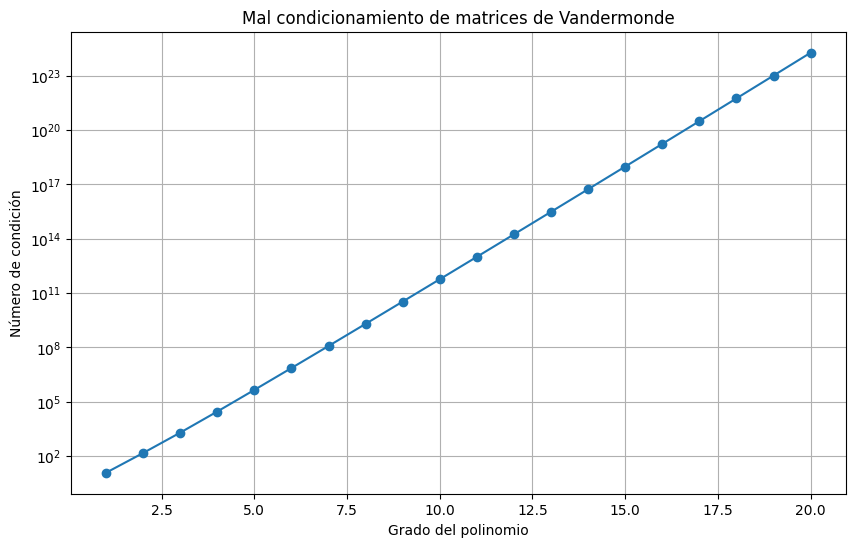

In [17]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

x = np.linspace(
    0,
    10,
    100
)

y = np.sin(x)

degrees = np.arange(
    1,
    21
)

condition_numbers = []

for degree in degrees:

    X = np.vander(
        x,
        degree + 1
    )

    condition_numbers.append(
        np.linalg.cond(X)
    )

plt.figure(figsize=(10, 6))

plt.semilogy(
    degrees,
    condition_numbers,
    marker="o"
)

plt.xlabel(
    "Grado del polinomio"
)

plt.ylabel(
    "Número de condición"
)

plt.title(
    "Mal condicionamiento de matrices de Vandermonde"
)

plt.grid()

plt.show()

El número de condición puede crecer brutalmente.

Eso significa que pequeños errores en los datos pueden producir grandes cambios en los coeficientes.

# 34. Una solución: escalamiento

Podemos transformar:

$x\in[0,10]$

a aproximadamente:

$z\in[-1,1]$.

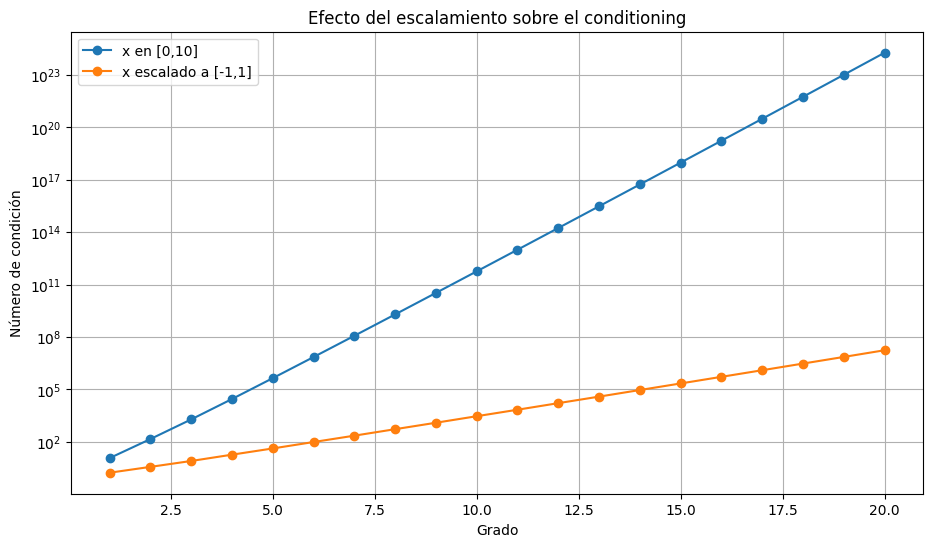

In [18]:
x_scaled = (
    2
    * (x - x.min())
    / (x.max() - x.min())
    - 1
)

condition_original = []
condition_scaled = []

for degree in degrees:

    X1 = np.vander(
        x,
        degree + 1
    )

    X2 = np.vander(
        x_scaled,
        degree + 1
    )

    condition_original.append(
        np.linalg.cond(X1)
    )

    condition_scaled.append(
        np.linalg.cond(X2)
    )


plt.figure(figsize=(11, 6))

plt.semilogy(
    degrees,
    condition_original,
    marker="o",
    label="x en [0,10]"
)

plt.semilogy(
    degrees,
    condition_scaled,
    marker="o",
    label="x escalado a [-1,1]"
)

plt.xlabel("Grado")
plt.ylabel("Número de condición")

plt.title(
    "Efecto del escalamiento sobre el conditioning"
)

plt.legend()
plt.grid()

plt.show()

Ésta es una de las razones por las que el escalamiento/normalización aparece constantemente en métodos numéricos y ML.

# 35. Ejemplo de vida real: GPS

Imagina que varios satélites determinan tu posición.

Conceptualmente se resuelve un problema inverso:

$\text{mediciones}
\rightarrow
\text{posición}$.

Si la geometría de los satélites es buena, pequeñas incertidumbres de medición producen pequeños errores de posición.

Pero con geometría desfavorable:

$\text{pequeño error en mediciones}$

puede producir:

$\text{gran error en posición}$.

Eso es esencialmente un problema de **conditioning**.

No necesariamente significa que el algoritmo GPS sea incorrecto.

El problema geométrico puede ser más sensible.

# 36. Ejemplo científico: inverse problems

En SciML tendrás problemas como:

$y=$ $F(\theta)+\epsilon$

donde:

- $(y)$: observaciones;
- $(F)$: simulador físico;
- $(\theta)$: parámetros desconocidos;
- $(\epsilon)$: ruido.

Quieres resolver:

$\theta^*
=$
$\arg\min_\theta
\|F(\theta)-y\|^2$

Pero podría ocurrir que:

$F(\theta_1)
\approx
F(\theta_2)$

aunque:

$\theta_1$

y

$\theta_2$

sean muy diferentes.

Entonces el problema inverso puede estar mal condicionado o incluso ser no identificable.

Eso es extremadamente importante en SciML.

# 37. Ejemplo: parámetros de una ODE

Consideremos:

$\frac{dy}{dt}
=$
$-ky$.

La solución:

$y(t)=$ $y_0e^{-kt}$.

Supongamos que queremos aprender $(k)$ a partir de mediciones.

Tenemos:

$y_{\text{obs}}(t_i)
=$
$y_0e^{-kt_i}
+
\epsilon_i$.

Podemos analizar cómo el ruido afecta la estimación de $(k)$.

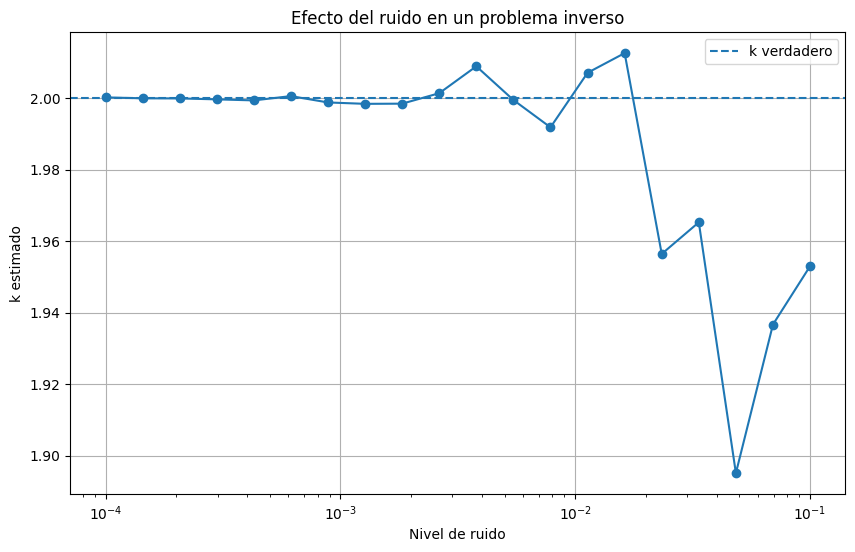

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

np.random.seed(42)

k_true = 2.0
y0 = 1.0

t = np.linspace(
    0,
    2,
    50
)

clean = (
    y0
    * np.exp(-k_true*t)
)

noise_levels = np.logspace(
    -4,
    -1,
    20
)

estimated_k = []

for sigma in noise_levels:

    noisy = (
        clean
        + sigma
        * np.random.randn(len(t))
    )

    def residual(params):

        k = params[0]

        prediction = (
            y0
            * np.exp(-k*t)
        )

        return (
            prediction
            - noisy
        )

    result = least_squares(
        residual,
        x0=[1.0]
    )

    estimated_k.append(
        result.x[0]
    )


plt.figure(figsize=(10, 6))

plt.semilogx(
    noise_levels,
    estimated_k,
    marker="o"
)

plt.axhline(
    k_true,
    linestyle="--",
    label="k verdadero"
)

plt.xlabel(
    "Nivel de ruido"
)

plt.ylabel(
    "k estimado"
)

plt.title(
    "Efecto del ruido en un problema inverso"
)

plt.legend()
plt.grid()

plt.show()

Este tipo de análisis es muy cercano a lo que harás en SciML.

# 38. Floating point también importa en Deep Learning

En ML/SciML no siempre trabajamos con `float64`.

Es común utilizar:

$\text{float32}$

y en GPUs incluso:

$\text{float16}$

o formatos como `bfloat16`.

Compara:

In [20]:
import numpy as np

for dtype in [
    np.float16,
    np.float32,
    np.float64
]:

    info = np.finfo(dtype)

    print(dtype)

    print(
        "epsilon:",
        info.eps
    )

    print(
        "máximo:",
        info.max
    )

    print(
        "mínimo normal:",
        info.tiny
    )

    print()

<class 'numpy.float16'>
epsilon: 0.000977
máximo: 65500.0
mínimo normal: 6.104e-05

<class 'numpy.float32'>
epsilon: 1.1920929e-07
máximo: 3.4028235e+38
mínimo normal: 1.1754944e-38

<class 'numpy.float64'>
epsilon: 2.220446049250313e-16
máximo: 1.7976931348623157e+308
mínimo normal: 2.2250738585072014e-308



Menor precisión significa potencialmente:

- más round-off;
- overflow;
- underflow;
- pérdida de gradientes pequeños.

Pero también:

- menor memoria;
- mayor velocidad;
- mejor utilización de GPUs.

De ahí surge **mixed precision training**.

# 39. Overflow y underflow


Supongamos:

$e^{1000}$.

In [21]:
import numpy as np

print(np.exp(1000))

inf


/tmp/ipykernel_71749/3929506849.py:3: RuntimeWarning: overflow encountered in exp
  print(np.exp(1000))


Puede producir:

```text
inf
```

Eso es **overflow**.

Ahora:

In [22]:
print(np.exp(-1000))

0.0


puede producir:

```text
0.0
```

Eso es **underflow**.

Matemáticamente:

$e^{-1000}>0$.

Pero numéricamente puede ser demasiado pequeño para representarlo de la forma esperada.

# 40. Ejemplo clásico en ML: softmax inestable

Softmax:

$p_i
=$
$\frac{e^{x_i}}
{\sum_j e^{x_j}}$.

Supongamos:

$x=
[1000,1001,1002]$.

Una implementación ingenua:

In [23]:
import numpy as np

x = np.array([
    1000.0,
    1001.0,
    1002.0
])

softmax = (
    np.exp(x)
    /
    np.sum(np.exp(x))
)

print(softmax)

[nan nan nan]


/tmp/ipykernel_71749/1919039740.py:10: RuntimeWarning: overflow encountered in exp
  np.exp(x)
/tmp/ipykernel_71749/1919039740.py:12: RuntimeWarning: overflow encountered in exp
  np.sum(np.exp(x))
/tmp/ipykernel_71749/1919039740.py:10: RuntimeWarning: invalid value encountered in divide
  np.exp(x)


puede sufrir overflow.

Pero matemáticamente podemos restar una constante $(c)$:

$\frac{e^{x_i-c}}
{\sum_j e^{x_j-c}}$.

Elegimos:

$c=\max(x)$.

Entonces:

In [24]:
shifted = (
    x
    - np.max(x)
)

softmax_stable = (
    np.exp(shifted)
    /
    np.sum(
        np.exp(shifted)
    )
)

print(
    softmax_stable
)

[0.09003057 0.24472847 0.66524096]


El resultado matemático es el mismo, pero el algoritmo es muchísimo más estable.

Otra vez:

$\boxed{
\text{misma matemática}
\neq
\text{misma estabilidad numérica}
}$

# 41. Un ejemplo avanzado que une casi todo

Consideremos la ecuación del calor:

$u_t=$ $\alpha u_{xx}$.

Discretizamos:

$u_{xx}
\approx
\frac{
u_{i+1}
-2u_i
+u_{i-1}
}{\Delta x^2}$.

Entonces:

$\frac{
u_i^{n+1}
-u_i^n
}{\Delta t}
=$
$\alpha
\frac{
u_{i+1}^n
-2u_i^n
+u_{i-1}^n
}{\Delta x^2}$.

Despejamos:

$
u_i^{n+1}
=$
$u_i^n
+
r
\left(
u_{i+1}^n
-2u_i^n
+u_{i-1}^n
\right)$

donde:

$\boxed{
r=
\frac{\alpha\Delta t}
{\Delta x^2}
}$

Para este método explícito necesitamos aproximadamente:

$
\boxed{
r\le\frac12
}$

para estabilidad en 1D.

# 42. Simulación estable vs inestable

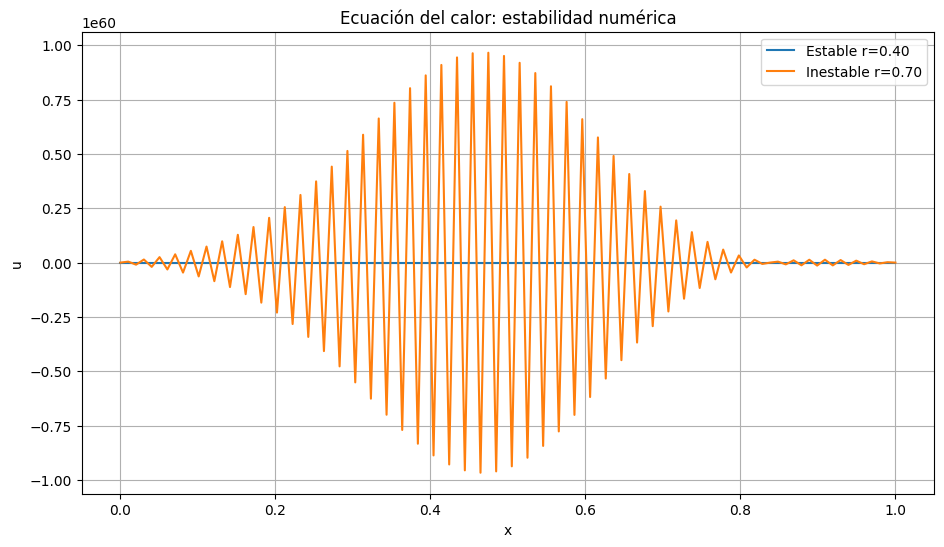

In [25]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 0.1

L = 1.0

Nx = 100

dx = L / (Nx - 1)

x = np.linspace(
    0,
    L,
    Nx
)

u0 = np.exp(
    -200
    * (x - 0.5)**2
)


def heat_equation(dt, steps):

    r = (
        alpha
        * dt
        / dx**2
    )

    u = u0.copy()

    history = [u.copy()]

    for _ in range(steps):

        u_new = u.copy()

        u_new[1:-1] = (
            u[1:-1]
            + r
            * (
                u[2:]
                - 2*u[1:-1]
                + u[:-2]
            )
        )

        u = u_new

        history.append(
            u.copy()
        )

    return (
        np.array(history),
        r
    )


dt_stable = (
    0.4
    * dx**2
    / alpha
)

dt_unstable = (
    0.7
    * dx**2
    / alpha
)


stable, r1 = heat_equation(
    dt_stable,
    300
)

unstable, r2 = heat_equation(
    dt_unstable,
    300
)


plt.figure(figsize=(11, 6))

plt.plot(
    x,
    stable[-1],
    label=f"Estable r={r1:.2f}"
)

plt.plot(
    x,
    unstable[-1],
    label=f"Inestable r={r2:.2f}"
)

plt.xlabel("x")
plt.ylabel("u")

plt.title(
    "Ecuación del calor: estabilidad numérica"
)

plt.legend()
plt.grid()

plt.show()

Aquí tienes simultáneamente:

- **truncation error:** reemplazamos derivadas por diferencias finitas;
- **round-off:** todos los cálculos usan floating point;
- **convergencia:** queremos que $(\Delta x,\Delta t\to0)$ produzca la solución correcta;
- **estabilidad:** debemos respetar la condición sobre $(r)$;
- **conditioning:** describe la sensibilidad del problema subyacente a perturbaciones;
- **error absoluto/relativo:** sirven para medir discrepancias.

Esto ya es análisis numérico muy relevante para SciML.

# 43. Error de discretización en una PDE

Supongamos que tenemos una solución de referencia $(u_{\mathrm{ref}})$ y una solución numérica $(u_h)$.

Podemos medir:

### Norma $(L^1)$

$E_1
=$
$\frac1N
\sum_i
|u_i-u_i^{ref}|
$

### Norma $(L^2)$

$E_2
=$
$\sqrt{
\frac1N
\sum_i
(u_i-u_i^{ref})^2
}
$

### Norma $(L^\infty)$

$E_\infty
=$
$\max_i
|u_i-u_i^{ref}|
$

En Python:

L1   = 0.01139533
L2   = 0.01265758
Linf = 0.01920100


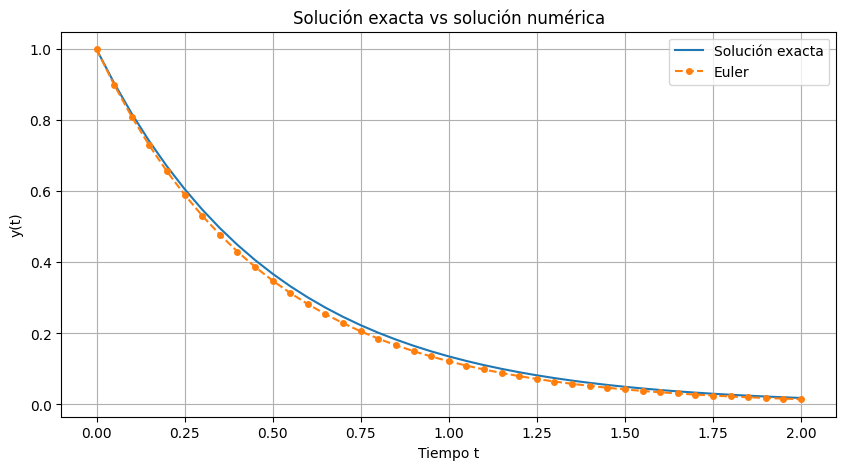

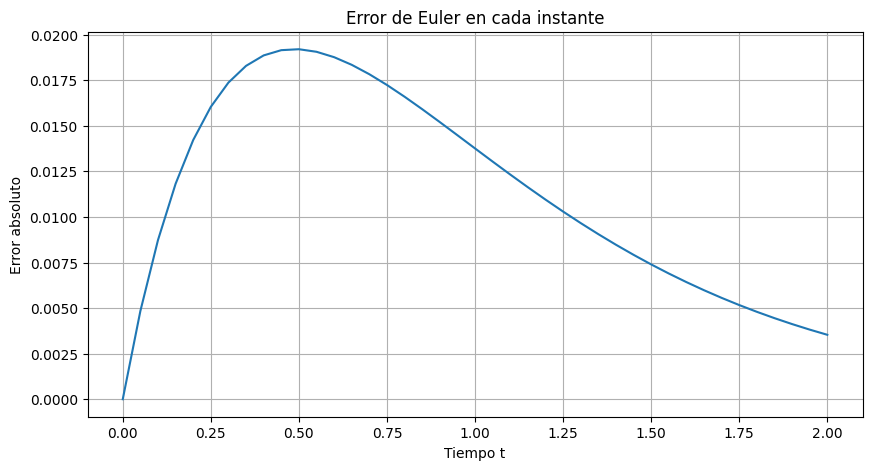

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Parámetros
# ==========================================

T = 2.0
h = 0.05

t = np.arange(0, T + h, h)

# ==========================================
# 2. Solución exacta (reference)
# ==========================================

reference = np.exp(-2 * t)

# ==========================================
# 3. Solución numérica con Euler
# ==========================================

numerical = np.zeros_like(t)

numerical[0] = 1.0

for n in range(len(t) - 1):
    numerical[n + 1] = numerical[n] + h * (-2 * numerical[n])

# ==========================================
# 4. Error punto por punto
# ==========================================

error = numerical - reference

absolute_error = np.abs(error)

# ==========================================
# 5. Normas del error
# ==========================================

L1 = np.mean(np.abs(error))

L2 = np.sqrt(np.mean(error**2))

Linf = np.max(np.abs(error))

print(f"L1   = {L1:.8f}")
print(f"L2   = {L2:.8f}")
print(f"Linf = {Linf:.8f}")

# ==========================================
# 6. Gráfica: solución exacta vs numérica
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    t,
    reference,
    label="Solución exacta"
)

plt.plot(
    t,
    numerical,
    "o--",
    markersize=4,
    label="Euler"
)

plt.xlabel("Tiempo t")
plt.ylabel("y(t)")
plt.title("Solución exacta vs solución numérica")

plt.legend()
plt.grid()

plt.show()

# ==========================================
# 7. Gráfica del error
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    t,
    absolute_error
)

plt.xlabel("Tiempo t")
plt.ylabel("Error absoluto")
plt.title("Error de Euler en cada instante")

plt.grid()

plt.show()

Estas métricas aparecerán constantemente cuando compares:

$\text{solver numérico}$

contra

$\text{modelo SciML}$.

# 44. ¿Cómo se conecta esto con PINNs?

Supongamos la PDE:

$u_t-\alpha u_{xx}=0$.

Una Physics-Informed Neural Network aproxima:

$u_\theta(x,t)$.

Después utiliza diferenciación automática para calcular:

$\frac{\partial u_\theta}{\partial t}$

y

$\frac{\partial^2u_\theta}{\partial x^2}$.

Construimos el residual:

$r_\theta(x,t)
=$
$u_{\theta,t}
-$
$\alpha u_{\theta,xx}$

y una loss:

$\mathcal{L}
=$
$\mathcal{L}_{data}
+$
$\lambda
\mathcal{L}_{physics}
$

con:

$\mathcal{L}_{physics}
=$
$\frac1N
\sum_i
|r_\theta(x_i,t_i)|^2$.

Ahora aparecen problemas numéricos como:

- precisión floating point;
- escalas muy diferentes entre términos de la loss;
- conditioning del problema;
- estabilidad de optimización;
- errores de discretización de datos;
- sensibilidad de parámetros;
- convergencia del entrenamiento.

Por eso el análisis numérico no es un tema secundario para SciML.

# 45. Un error conceptual que debes evitar

Estos términos **no son sinónimos**.

Puedes organizarlos así:

| Concepto | Pregunta |
|---|---|
| Error absoluto | ¿Cuánto me equivoqué en unidades reales? |
| Error relativo | ¿Qué tan grande es el error respecto al valor? |
| Truncation error | ¿Qué perdí al reemplazar algo exacto/infinito por una aproximación? |
| Round-off | ¿Qué error introdujo la precisión finita? |
| Floating point | ¿Cómo representa números reales la computadora? |
| Stability | ¿El algoritmo amplifica perturbaciones/errores? |
| Convergence | ¿Al refinar la aproximación llego a la solución correcta? |
| Conditioning | ¿El problema matemático es sensible a perturbaciones? |

Una distinción particularmente importante es:

$\text{conditioning}
\neq
\text{stability}
\neq
\text{convergence}
$

# 46. Mapa mental completo

Quiero que visualices todo así:

$\boxed{
\text{Problema físico}
}
$

por ejemplo:

$u_t=\alpha u_{xx}$.

↓

lo discretizamos:

$\boxed{
\text{Truncation error}
}$

↓

lo calculamos en una computadora:

$\boxed{
\text{Floating point}
}
$

↓

que introduce:

$\boxed{
\text{Round-off error}
}
$

↓

preguntamos si el problema mismo es sensible:

$
\boxed{
\text{Conditioning}
}
$

↓

preguntamos si nuestro algoritmo controla perturbaciones:

$\boxed{
\text{Stability}
}
$

↓

refinamos:

$h\rightarrow0
$

y preguntamos:

$\boxed{
\text{Convergence}
}$

↓

finalmente medimos:

$\boxed{
E_{\mathrm{abs}},
E_{\mathrm{rel}},
L^1,L^2,L^\infty
}
$

| **Inicio**         | **Siguiente 2**                                    |
| ------------------  | -------------------------------------------------- |
| [🏠](../README.md)  | [⏩](./6_2_Root_finding.ipynb) |